# 💳 Credit Card Fraud Detection — Imbalanced Classification with Threshold Optimisation

## Step 1: Problem Framing & Theory Notes

**Q1. Why is Accuracy a terrible metric for fraud detection? If 99.83% of transactions are legitimate and the model predicts everything as 'Not Fraud', what accuracy does it get? What are Precision and Recall for the Fraud class?**

**Answer:** Accuracy is dominated by the majority class. A model that predicts *Not Fraud* for every transaction is **99.83% accurate** yet completely useless:
- **Recall (Fraud) = 0%** → not a single fraud is caught.
- **Precision (Fraud) = 0 / 0 → undefined** (reported as 0), because the model never flags anything.

**Q2. What is the Precision-Recall tradeoff? Draw a 2x2 confusion matrix and explain what happens when the threshold is lowered from 0.5 to 0.2.**

**Answer:**

| | **Predicted Fraud** | **Predicted Legit** |
|---|---|---|
| **Actual Fraud** | TP (fraud caught) | FN (fraud missed) |
| **Actual Legit** | FP (false alarm) | TN (correctly ignored) |

Precision = `TP / (TP + FP)` and Recall = `TP / (TP + FN)`. Lowering the threshold from 0.5 to 0.2 makes the model flag more transactions: some **FN turn into TP** (recall goes up) but some **TN turn into FP** (precision goes down). Precision and recall pull in opposite directions, so the threshold must be chosen using business costs.

**Q3. Explain 3 strategies to handle extreme class imbalance: (a) Random Undersampling, (b) SMOTE Oversampling, (c) `class_weight='balanced'`. Pros and cons?**

**Answer:**

| Strategy | How it works | Pros | Cons |
|---|---|---|---|
| **(a) Random Undersampling** | Randomly removes majority-class rows | Fast, small training set, boosts recall | Throws away information, many false alarms, unstable with few rows |
| **(b) SMOTE** | Creates synthetic minority points by interpolating between neighbouring fraud cases | No information loss, richer fraud region | Can create unrealistic or noisy points, slower, must be applied to training data only |
| **(c) `class_weight='balanced'`** | Penalises minority-class errors more in the loss function | No change to the data, simple, no leakage risk | Only for models that support it, can over-flag (low precision), probabilities become inflated |

**Q4. What is the Precision-Recall AUC (PR-AUC)? Why is it preferred over ROC-AUC for extreme imbalance?**

**Answer:** PR-AUC is the area under the Precision-Recall curve (computed here with `average_precision_score`); it summarises the precision-recall tradeoff across all thresholds and focuses only on the fraud class. ROC-AUC uses the False Positive Rate, whose denominator is the huge number of legitimate transactions, so even many false alarms keep FPR tiny and ROC-AUC looks excellent (≈ 0.99) for weak models. The PR-AUC baseline equals the fraud rate (≈ 0.17%), so it exposes real differences between models.

**Q5. In fraud detection, which is more costly: a False Positive or a False Negative? Give a specific business example of each.**

**Answer:**
- **False Negative (missed fraud) — usually more costly.** Example: a stolen card makes a ₹4,500 purchase that is approved; the company absorbs the loss, pays the chargeback and loses customer trust.
- **False Positive (legit flagged as fraud).** Example: a genuine customer's wedding-shopping payment is blocked, an analyst spends time (≈ ₹150) reviewing it, and the annoyed customer may switch to another app.

A false negative costs far more per case, but too many false positives overload the risk team and hurt customers, so both must be balanced.

## Step 2: Dataset Loading & EDA

### 2.1 Load & Sample

In [1]:
import warnings
import json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import xgboost

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix,
    auc
)
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

np.random.seed(42)
warnings.filterwarnings('ignore')

# Project layout:  data/creditcard.csv  |  notebook/ (this file)  |  model/ (exported .pkl)
DATA_PATH = Path('../data/creditcard.csv')
MODEL_DIR = Path('../model')

In [2]:
df = pd.read_csv(DATA_PATH)

print("Full dataset shape:", df.shape)
print("Missing values    :", df.isnull().sum().sum())
print()
print("Class distribution (full data):")
print(df['Class'].value_counts(normalize=True).round(5))

Full dataset shape: (284807, 31)
Missing values    : 0

Class distribution (full data):
Class
0    0.99827
1    0.00173
Name: proportion, dtype: float64


**📝 Interpretation:** The dataset has 284,807 transactions and **no missing values**. Only 492 (0.173%) are fraud, roughly 1 fraud for every 580 legitimate transactions, so the imbalance is extreme.

In [3]:
X_full = df.drop(columns='Class')
y_full = df['Class']

# Stratified 50,000-row sample (only the FIRST split is used)
X_sample, _, y_sample, _ = train_test_split(
    X_full, y_full, train_size=50000, stratify=y_full, random_state=42
)

df_sample = X_sample.copy()
df_sample['Class'] = y_sample
df_sample = df_sample.reset_index(drop=True)

ratio_check = pd.DataFrame({
    'Rows': [len(df), len(df_sample)],
    'Fraud Count': [int(df['Class'].sum()), int(df_sample['Class'].sum())],
    'Fraud %': [df['Class'].mean() * 100, df_sample['Class'].mean() * 100]
}, index=['Full Data', 'Sample (50,000)']).round(4)
display(ratio_check)

display(df_sample[['Time', 'Amount']].describe().T)

,Rows,Fraud Count,Fraud %
Full Data,284807,492,0.1727
"Sample (50,000)",50000,86,0.1720


,count,mean,std,min,25%,50%,75%,max
Time,50000.0,94977.935540,47475.507310,0.0,54423.50,84852.0,139392.250,172787.0
Amount,50000.0,86.942063,226.984602,0.0,5.85,22.0,76.275,8360.0


**📝 Interpretation:** The stratified 50,000-row sample keeps **86 frauds (0.172%** vs 0.173% in the full data), so the imbalance is preserved. `Time` covers about two days (0 to 172,787 seconds) and `Amount` is heavily right-skewed: median 22, mean 86.9, maximum 8,360.

### 2.2 Target & Feature Analysis

#### Countplot of Class (log scale)

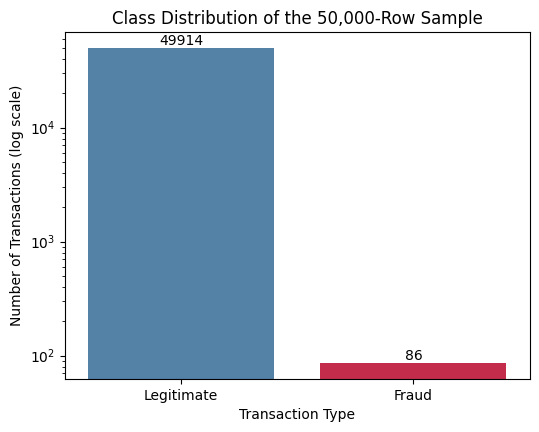

In [4]:
eda = df_sample.assign(Type=df_sample['Class'].map({0: 'Legitimate', 1: 'Fraud'}))

plt.figure(figsize=(6, 4.5))
ax = sns.countplot(data=eda, x='Type', order=['Legitimate', 'Fraud'], hue='Type',
                   palette={'Legitimate': 'steelblue', 'Fraud': 'crimson'}, legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%d')
plt.yscale('log')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions (log scale)')
plt.title('Class Distribution of the 50,000-Row Sample')
plt.show()

**📝 Interpretation:** On the log scale the imbalance is visible: 49,914 legitimate vs 86 fraud transactions, a bar about 580 times shorter. On a normal scale the fraud bar would be almost invisible.

#### Amount: Fraud vs Legitimate

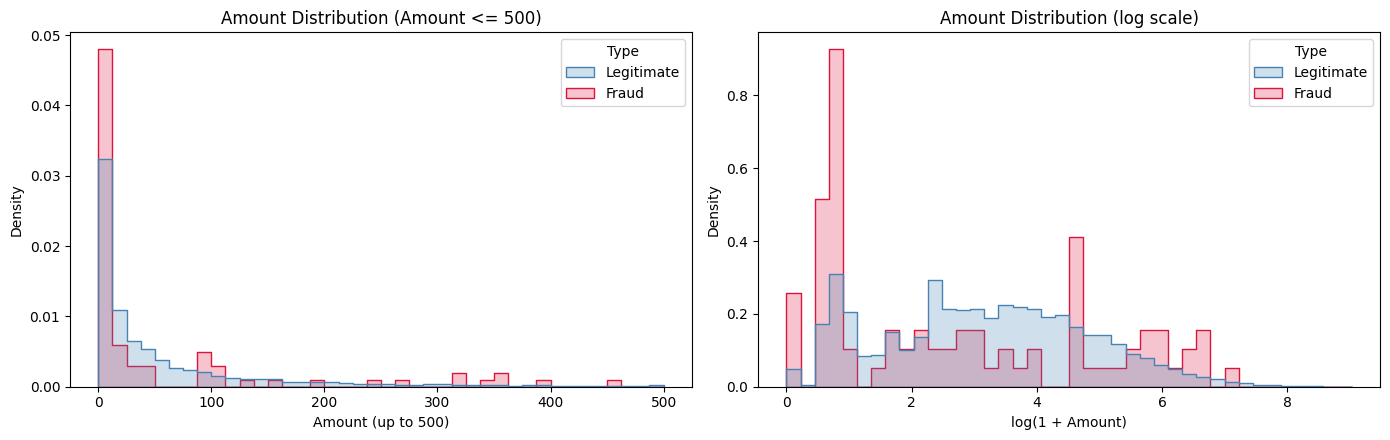

,count,mean,median,max
Type,,,,
Fraud,86,112.08,7.36,1335.0
Legitimate,49914,86.90,22.00,8360.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(data=eda[eda['Amount'] <= 500], x='Amount', hue='Type', stat='density',
             common_norm=False, bins=40, element='step', palette={'Legitimate': 'steelblue', 'Fraud': 'crimson'}, ax=axes[0])
axes[0].set_xlabel('Amount (up to 500)')
axes[0].set_ylabel('Density')
axes[0].set_title('Amount Distribution (Amount <= 500)')

sns.histplot(data=eda.assign(Amount_log_plot=np.log1p(eda['Amount'])), x='Amount_log_plot', hue='Type', stat='density',
             common_norm=False, bins=40, element='step', palette={'Legitimate': 'steelblue', 'Fraud': 'crimson'}, ax=axes[1])
axes[1].set_xlabel('log(1 + Amount)')
axes[1].set_ylabel('Density')
axes[1].set_title('Amount Distribution (log scale)')

plt.tight_layout()
plt.show()

display(eda.groupby('Type')['Amount'].agg(['count', 'mean', 'median', 'max']).round(2))

**📝 Interpretation:** Fraud has a **smaller typical amount**: median 7.36 vs 22.00 for legitimate transactions, with a big spike of very small amounts. The fraud mean is higher (112 vs 87) only because a few large frauds (up to 1,335) pull it up, so fraud is mostly small with a heavy tail.

#### Time: Fraud vs Legitimate

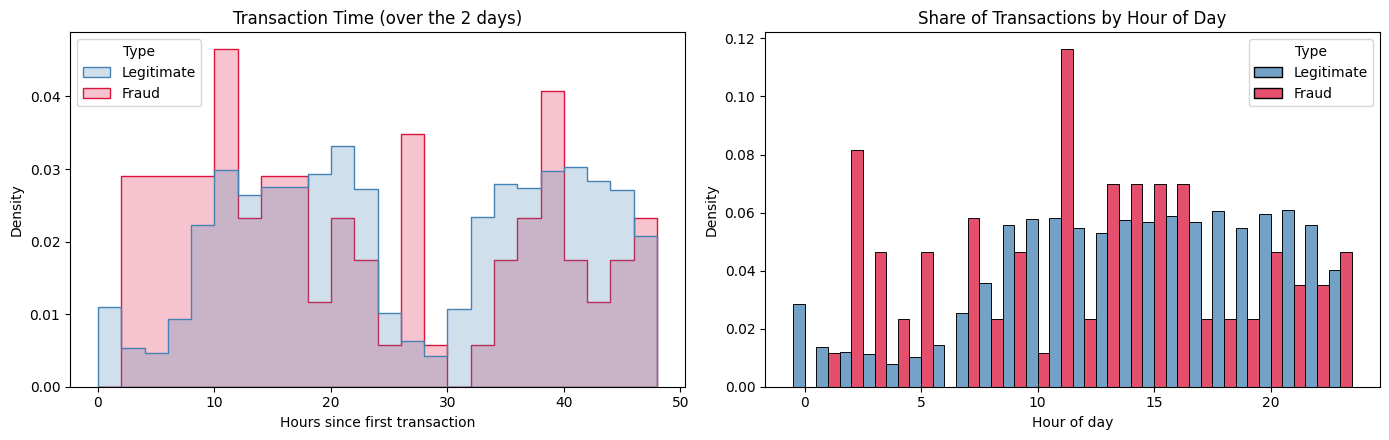

Share of transactions between 00:00 and 05:59:
Type
Fraud         20.9 %
Legitimate     8.4 %
dtype: object


In [6]:
eda['Hour_of_Day'] = (eda['Time'] % 86400) // 3600

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(data=eda.assign(Time_hours=eda['Time'] / 3600), x='Time_hours', hue='Type', stat='density',
             common_norm=False, bins=24, element='step', palette={'Legitimate': 'steelblue', 'Fraud': 'crimson'}, ax=axes[0])
axes[0].set_xlabel('Hours since first transaction')
axes[0].set_ylabel('Density')
axes[0].set_title('Transaction Time (over the 2 days)')

sns.histplot(data=eda, x='Hour_of_Day', hue='Type', stat='density', common_norm=False, discrete=True,
             multiple='dodge', palette={'Legitimate': 'steelblue', 'Fraud': 'crimson'}, ax=axes[1])
axes[1].set_xlabel('Hour of day')
axes[1].set_ylabel('Density')
axes[1].set_title('Share of Transactions by Hour of Day')

plt.tight_layout()
plt.show()

hour_share = eda.groupby('Type')['Hour_of_Day'].value_counts(normalize=True).unstack(0).fillna(0)
night_share = hour_share.loc[0:5].sum()
print("Share of transactions between 00:00 and 05:59:")
print((night_share * 100).round(1).astype(str) + ' %')

**📝 Interpretation:** Legitimate traffic follows a clear day-night rhythm (few transactions in the early hours), but fraud does not: **20.9% of frauds** happen between 00:00 and 05:59 against only **8.4%** of legitimate transactions (about 2.5 times more). With just 86 frauds, single hour bars are noisy, but the night-time skew is clear.

#### Correlation Heatmap: V1-V10 vs Class

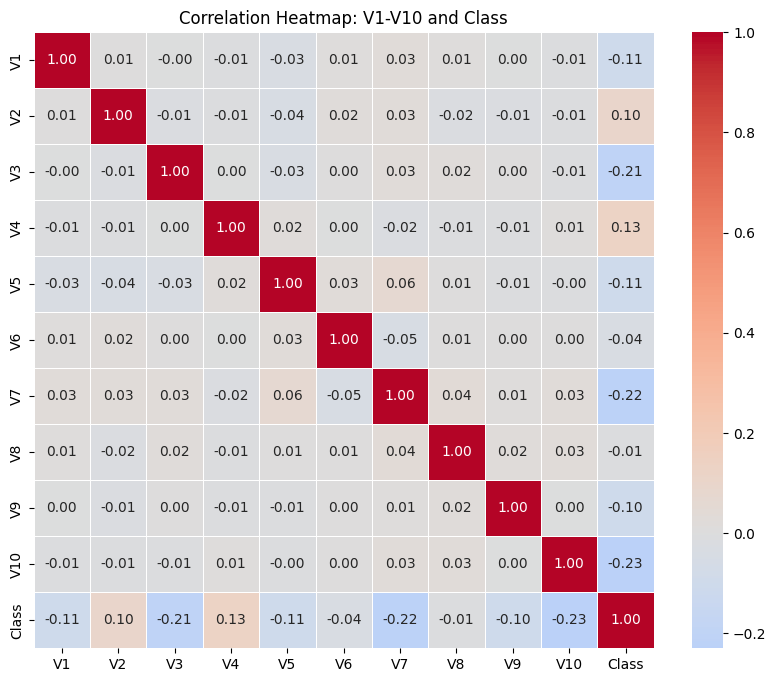

V-features most correlated with Fraud (absolute order):
V10   -0.230
V7    -0.216
V3    -0.205
V4     0.131
V5    -0.108
V1    -0.108
V9    -0.105
V2     0.099
V6    -0.036
V8    -0.009
Name: Class, dtype: float64


In [7]:
corr_cols = [f'V{i}' for i in range(1, 11)] + ['Class']
corr_matrix = df_sample[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap: V1-V10 and Class')
plt.show()

corr_with_class = corr_matrix['Class'].drop('Class').sort_values(key=abs, ascending=False)
print("V-features most correlated with Fraud (absolute order):")
print(corr_with_class.round(3))

**📝 Interpretation:** The V-features most correlated with fraud are **V10 (-0.23), V7 (-0.22) and V3 (-0.21)** (negative) and V4 (+0.13) (positive). All correlations are modest, so no single feature defines fraud and a non-linear model such as XGBoost should help.

#### 📌 Key Insight Check: do fraudulent transactions have smaller amounts and cluster at specific times?

- **Smaller amounts → confirmed (for the typical case):** fraud median 7.36 vs 22.00, although the fraud mean is higher because of a few large cases.
- **Specific time windows → partly confirmed:** frauds are over-represented at night (20.9% vs 8.4% between 00:00 and 05:59), while legitimate traffic drops at night. With only 86 frauds the exact hours are noisy, so `Hour` is a useful but weak feature.

## Step 3: Data Preprocessing & Feature Engineering

### 3.1 Feature Engineering

In [8]:
df_fe = df_sample.copy()

df_fe['Amount_log'] = np.log1p(df_fe['Amount'])             # fixes the heavy right skew of Amount
df_fe['Hour'] = (df_fe['Time'] % 86400) // 3600             # hour of day (0-23) from seconds since first transaction
df_fe = df_fe.drop(columns=['Time', 'Amount'])              # original columns no longer needed

print(f"Skewness  Amount: {df_sample['Amount'].skew():.2f}  →  Amount_log: {df_fe['Amount_log'].skew():.2f}")
print("Columns now:", df_fe.columns.tolist())
df_fe[['Amount_log', 'Hour', 'Class']].head()

Skewness  Amount: 9.47  →  Amount_log: 0.16
Columns now: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Class', 'Amount_log', 'Hour']


,Amount_log,Hour,Class
0,3.671479,9.0,0
1,3.660737,12.0,0
2,4.262680,22.0,0
3,4.987025,12.0,0
4,0.693147,11.0,0


**📝 Interpretation:** Skewness falls from **9.47** (`Amount`) to **0.16** (`Amount_log`), so the log transform makes the amount distribution almost symmetric. `Hour` is now an integer from 0 to 23, and the raw `Time` and `Amount` columns are removed.

### 3.2 Train-Test Split

> 📝 **Order note:** the split is done *before* scaling (the exam lists scaling first) so that the scaler learns its mean/std from the **training data only**. This avoids leaking test-set information.

In [9]:
feature_columns = [col for col in df_fe.columns if col != 'Class']
X = df_fe[feature_columns]
y = df_fe['Class']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train shape:", X_train_raw.shape)
print("Test shape :", X_test_raw.shape)

split_check = pd.DataFrame({
    'Train Count': y_train.value_counts().sort_index(),
    'Train %': (y_train.value_counts(normalize=True).sort_index() * 100).round(3),
    'Test Count': y_test.value_counts().sort_index(),
    'Test %': (y_test.value_counts(normalize=True).sort_index() * 100).round(3)
})
split_check.index = ['Legitimate (0)', 'Fraud (1)']
display(split_check)

Train shape: (40000, 30)
Test shape : (10000, 30)


,Train Count,Train %,Test Count,Test %
Legitimate (0),39931,99.828,9983,99.83
Fraud (1),69,0.172,17,0.17


**📝 Interpretation:** Stratification worked: 40,000 train rows (69 frauds, 0.172%) and 10,000 test rows (17 frauds, 0.17%). The test set has only 17 frauds, so each missed fraud changes recall by about 6 percentage points.

### 3.3 Scaling (StandardScaler on Amount_log and Hour only)

In [10]:
scale_cols = ['Amount_log', 'Hour']     # V1-V28 are already PCA-scaled → passed through untouched

scaler_preprocessor = ColumnTransformer(
    [('scaler', StandardScaler(), scale_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False
)
scaler_preprocessor.set_output(transform='pandas')

# Fit on TRAIN only → transform both. From here on X_train / X_test are the scaled versions.
X_train = scaler_preprocessor.fit_transform(X_train_raw)
X_test = scaler_preprocessor.transform(X_test_raw)

print("Scaled columns (train) → mean / std:")
display(X_train[scale_cols].agg(['mean', 'std']).round(3))

Scaled columns (train) → mean / std:


,Amount_log,Hour
mean,-0.0,0.0
std,1.0,1.0


**📝 Interpretation:** After scaling on the training data, `Amount_log` and `Hour` have mean 0 and standard deviation 1. V1-V28 are left untouched because they are already PCA-scaled.

### 3.4 Imbalance Handling — Three Strategies

Original     : Counter({0: 39931, 1: 69})
SMOTE        : Counter({0: 39931, 1: 3993})
Undersampled : Counter({0: 690, 1: 69})


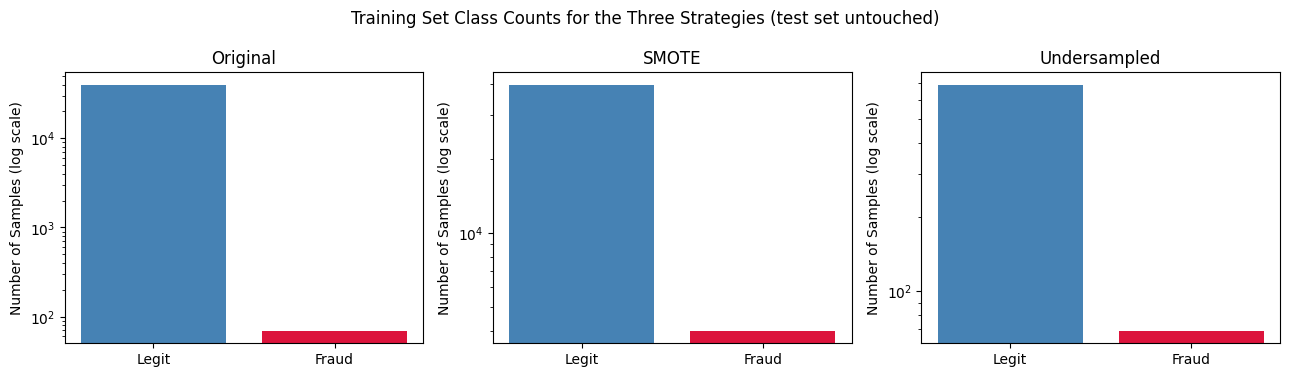

In [11]:
# Strategy 1: Original (imbalanced) → X_train, y_train (no change)

# Strategy 2: SMOTE → fraud raised to 10% of the majority class
smote = SMOTE(random_state=42, sampling_strategy=0.1)
X_smote, y_smote = smote.fit_resample(X_train, y_train)

# Strategy 3: Random Under-Sampling → fraud = 10% of the (reduced) majority class
under_sampler = RandomUnderSampler(random_state=42, sampling_strategy=0.1)
X_under, y_under = under_sampler.fit_resample(X_train, y_train)

print("Original     :", Counter(y_train.tolist()))
print("SMOTE        :", Counter(y_smote.tolist()))
print("Undersampled :", Counter(y_under.tolist()))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, labels) in zip(axes, {'Original': y_train, 'SMOTE': y_smote, 'Undersampled': y_under}.items()):
    counts = labels.value_counts().sort_index()
    ax.bar(['Legit', 'Fraud'], counts.values, color=['steelblue', 'crimson'])
    ax.set_yscale('log')
    ax.set_title(name)
    ax.set_ylabel('Number of Samples (log scale)')
fig.suptitle('Training Set Class Counts for the Three Strategies (test set untouched)')
plt.tight_layout()
plt.show()

**📝 Interpretation:** Original: 39,931 legit / 69 fraud. SMOTE grows the fraud class to 3,993 (10% of the majority). Under-sampling keeps all 69 frauds but cuts the legitimate class to 690, so the training set shrinks from 40,000 to only 759 rows. The test set was never touched.

## Step 4: Model Building — Logistic Regression & Random Forest

### 4.0 Reality Check: The Accuracy Trap

In [12]:
# A "model" that always predicts Not Fraud
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print(f"Accuracy          : {accuracy_score(y_test, dummy_pred):.4%}")
print(f"Precision (Fraud) : {precision_score(y_test, dummy_pred, zero_division=0):.4f}")
print(f"Recall (Fraud)    : {recall_score(y_test, dummy_pred):.4f}")
print(f"Frauds caught     : 0 of {int(y_test.sum())}")

Accuracy          : 99.8300%
Precision (Fraud) : 0.0000
Recall (Fraud)    : 0.0000
Frauds caught     : 0 of 17


**📝 Interpretation:** The 'always Not Fraud' model gets **99.83% accuracy** yet catches **0 of 17** frauds (precision 0, recall 0). This is the accuracy trap: a useless model looks almost perfect.

### 4.1 Logistic Regression — Three Variants

In [13]:
model_results = []     # one dict per evaluated model / threshold → final comparison table
curve_store = {}       # model name → fraud probabilities on the test set (for PR curves)


def evaluate_fraud_model(model_name, y_true, y_prob, threshold=0.5, curve_key='auto'):
    """Evaluate fraud probabilities at a given threshold and save the result row"""
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    row = {
        'Model': model_name,
        'Precision (Fraud)': precision_score(y_true, y_pred, zero_division=0),
        'Recall (Fraud)': recall_score(y_true, y_pred),
        'F1 (Fraud)': f1_score(y_true, y_pred),
        'PR-AUC': average_precision_score(y_true, y_prob),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'Threshold': threshold,
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn
    }
    model_results.append(row)
    if curve_key == 'auto':
        curve_key = model_name
    if curve_key is not None:
        curve_store[curve_key] = y_prob
    return row


def plot_pr_curves(model_names, title):
    plt.figure(figsize=(8, 6))
    for name in model_names:
        prec, rec, _ = precision_recall_curve(y_test, curve_store[name])
        plt.plot(rec, prec, linewidth=2, label=f"{name} (PR-AUC = {average_precision_score(y_test, curve_store[name]):.3f})")
    plt.axhline(y_test.mean(), color='gray', linestyle='--', label=f'No-skill baseline ({y_test.mean():.4f})')
    plt.xlabel('Recall (Fraud)')
    plt.ylabel('Precision (Fraud)')
    plt.title(title)
    plt.xlim(0, 1.0)
    plt.ylim(0, 1.02)
    plt.legend(loc='lower left')
    plt.grid(alpha=0.3)
    plt.show()


lr_variants = {
    'Logistic Regression (Original, balanced weights)': {'strategy': 'Original', 'X': X_train, 'y': y_train, 'class_weight': 'balanced'},
    'Logistic Regression (SMOTE)': {'strategy': 'SMOTE', 'X': X_smote, 'y': y_smote, 'class_weight': None},
    'Logistic Regression (Undersampled)': {'strategy': 'Undersampled', 'X': X_under, 'y': y_under, 'class_weight': None}
}

lr_models = {}
for name, cfg in lr_variants.items():
    lr = LogisticRegression(class_weight=cfg['class_weight'], max_iter=1000, random_state=42)
    lr.fit(cfg['X'], cfg['y'])
    lr_models[name] = lr
    evaluate_fraud_model(name, y_test, lr.predict_proba(X_test)[:, 1])

lr_compare = pd.DataFrame(model_results)[['Model', 'Precision (Fraud)', 'Recall (Fraud)', 'F1 (Fraud)', 'PR-AUC', 'ROC-AUC', 'FP', 'FN']]

# Best strategy = highest PR-AUC (primary metric); ROC-AUC is shown only for contrast
best_lr_name = lr_compare.loc[lr_compare['PR-AUC'].idxmax(), 'Model']
best_strategy = lr_variants[best_lr_name]['strategy']
lr_compare['Best'] = np.where(lr_compare['Model'] == best_lr_name, '⭐', '')
display(lr_compare.round(4))

print(f"🎯 Best imbalance strategy for Logistic Regression (by PR-AUC): {best_strategy}")

,Model,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC,ROC-AUC,FP,FN,Best
0,"Logistic Regression (Original, balanced weights)",0.0649,1.0000,0.1219,0.7814,0.9988,245,0,
1,Logistic Regression (SMOTE),0.3091,1.0000,0.4722,0.8144,0.9994,38,0,⭐
2,Logistic Regression (Undersampled),0.2286,0.9412,0.3678,0.8093,0.9987,54,1,


🎯 Best imbalance strategy for Logistic Regression (by PR-AUC): SMOTE


**📝 Interpretation:** ROC-AUC is about 0.999 for all three variants, so it cannot tell them apart, while PR-AUC can (0.814 / 0.809 / 0.781). **SMOTE is the best strategy** (PR-AUC 0.814): recall 1.00 with 38 false alarms, versus 245 false alarms with balanced class weights and 54 with under-sampling (which also misses 1 fraud). Precision is still only 0.31, so logistic regression is too simple for this problem.

### 4.2 Random Forest — Best Imbalance Strategy

Training Random Forest on the 'SMOTE' training set: Counter({0: 39931, 1: 3993})
Precision (Fraud): 0.875
Recall (Fraud)   : 0.8235
F1 (Fraud)       : 0.8485
PR-AUC           : 0.872
Trapezoid PR-AUC : 0.875 (close to average precision, as expected)


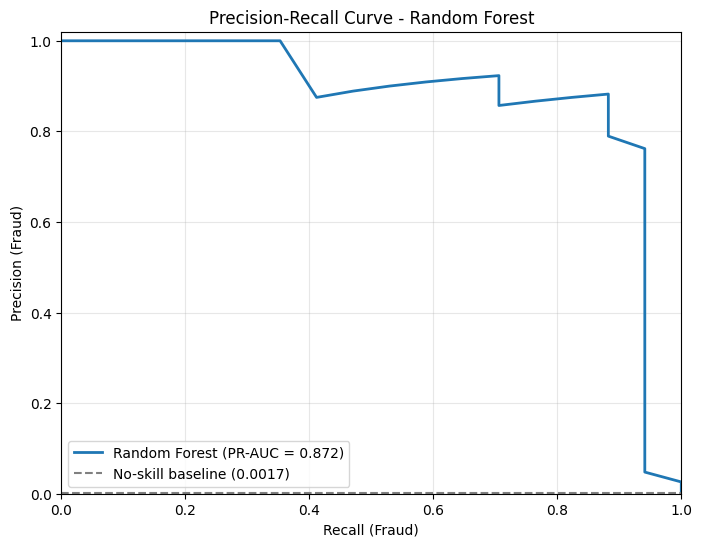

In [14]:
X_best = lr_variants[best_lr_name]['X']
y_best = lr_variants[best_lr_name]['y']
print(f"Training Random Forest on the '{best_strategy}' training set:", Counter(y_best.tolist()))

rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
rf_model.fit(X_best, y_best)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
rf_row = evaluate_fraud_model('Random Forest', y_test, y_prob_rf)

print("Precision (Fraud):", round(rf_row['Precision (Fraud)'], 4))
print("Recall (Fraud)   :", round(rf_row['Recall (Fraud)'], 4))
print("F1 (Fraud)       :", round(rf_row['F1 (Fraud)'], 4))
print("PR-AUC           :", round(rf_row['PR-AUC'], 4))

# Manual check: trapezoid area under the PR curve vs sklearn's average precision
prec_rf, rec_rf, _ = precision_recall_curve(y_test, y_prob_rf)
print("Trapezoid PR-AUC :", round(auc(rec_rf, prec_rf), 4), "(close to average precision, as expected)")

plot_pr_curves(['Random Forest'], 'Precision-Recall Curve - Random Forest')

**📝 Interpretation:** Random Forest (trained on the SMOTE set) gives precision 0.93, recall 0.76, F1 0.84 and PR-AUC 0.870. Precision jumps from 0.31 (logistic regression) to 0.93, but it misses 4 of the 17 frauds. The trapezoid PR-AUC matches `average_precision_score`, confirming the metric.

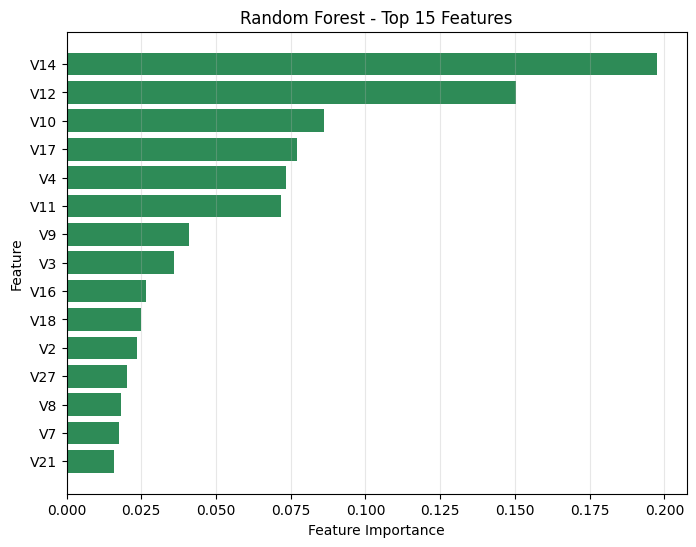

Top 5 V-features: ['V14', 'V12', 'V10', 'V17', 'V4']


In [15]:
rf_importance = pd.DataFrame({
    'Feature': X_best.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(8, 6))
plt.barh(rf_importance['Feature'], rf_importance['Importance'], color='seagreen')
plt.gca().invert_yaxis()
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Random Forest - Top 15 Features')
plt.grid(axis='x', alpha=0.3)
plt.show()

print("Top 5 V-features:", [f for f in rf_importance['Feature'] if f.startswith('V')][:5])

**📝 Interpretation:** The most predictive features are **V14, V12, V10, V17 and V4**. V10 and V4 also showed up in the EDA correlations, so a handful of PCA components carry most of the fraud signal.

## Step 5: Model Building — XGBoost with Full Tuning

### 5.1 XGBoost Baseline

scale_pos_weight (ratio) = 39931 / 69 = 578.71
Precision (Fraud): 1.0
Recall (Fraud)   : 0.8235
F1 (Fraud)       : 0.9032
PR-AUC           : 0.9012


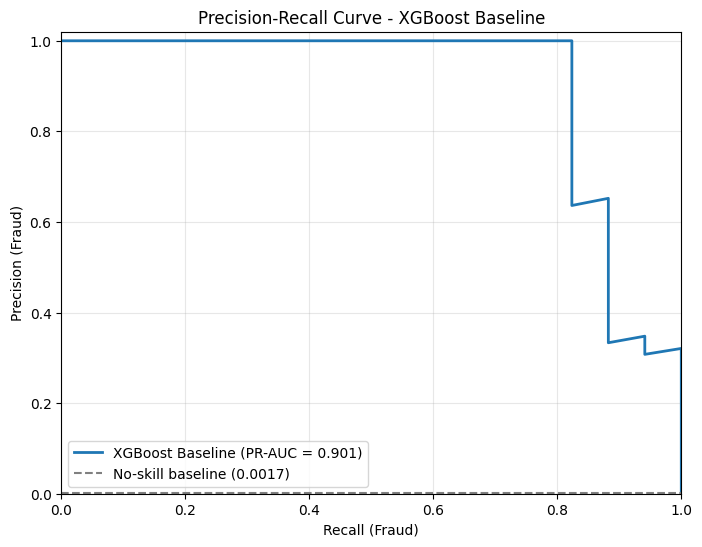

In [16]:
# scale_pos_weight = count(non-fraud) / count(fraud) in the ORIGINAL training data
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight (ratio) = {(y_train == 0).sum()} / {(y_train == 1).sum()} = {ratio:.2f}")

xgb_base = XGBClassifier(
    n_estimators=200, learning_rate=0.1, max_depth=4,
    scale_pos_weight=ratio, random_state=42, eval_metric='logloss'
)
xgb_base.fit(X_train, y_train)

y_prob_xgb_base = xgb_base.predict_proba(X_test)[:, 1]
xgb_base_row = evaluate_fraud_model('XGBoost Baseline', y_test, y_prob_xgb_base)

print("Precision (Fraud):", round(xgb_base_row['Precision (Fraud)'], 4))
print("Recall (Fraud)   :", round(xgb_base_row['Recall (Fraud)'], 4))
print("F1 (Fraud)       :", round(xgb_base_row['F1 (Fraud)'], 4))
print("PR-AUC           :", round(xgb_base_row['PR-AUC'], 4))

plot_pr_curves(['XGBoost Baseline'], 'Precision-Recall Curve - XGBoost Baseline')

**📝 Interpretation:** The XGBoost baseline already beats the Random Forest: precision 1.00, recall 0.82, F1 0.90 and PR-AUC 0.901. `scale_pos_weight = 578.71` tells the model that one fraud case is worth about 579 legitimate ones during training.

### 5.2 Hyperparameter Tuning

In [17]:
xgb_param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}

xgb_random = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric='logloss'),
    param_distributions=xgb_param_dist,
    n_iter=15,
    cv=3,
    scoring='average_precision',
    random_state=42
)
xgb_random.fit(X_train, y_train)

print("Best parameters  :", xgb_random.best_params_)
print("Best CV PR-AUC   :", round(xgb_random.best_score_, 4))

xgb_tuned = xgb_random.best_estimator_
y_prob_xgb_tuned = xgb_tuned.predict_proba(X_test)[:, 1]
xgb_tuned_row = evaluate_fraud_model('XGBoost Tuned (default 0.5)', y_test, y_prob_xgb_tuned, curve_key='XGBoost Tuned')

tuning_compare = pd.DataFrame([xgb_base_row, xgb_tuned_row])[['Model', 'Precision (Fraud)', 'Recall (Fraud)', 'F1 (Fraud)', 'PR-AUC']]
tuning_compare['Model'] = ['XGBoost Baseline', 'XGBoost Tuned']
display(tuning_compare.round(4))
print(f"PR-AUC before tuning: {xgb_base_row['PR-AUC']:.4f}  →  after tuning: {xgb_tuned_row['PR-AUC']:.4f}")

Best parameters  : {'subsample': 0.6, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Best CV PR-AUC   : 0.8043


,Model,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC
0,XGBoost Baseline,1.0,0.8235,0.9032,0.9012
1,XGBoost Tuned,1.0,0.8235,0.9032,0.9144


PR-AUC before tuning: 0.9012  →  after tuning: 0.9144


**📝 Interpretation:** Randomized search (15 candidates, 3-fold CV, scored on PR-AUC) picks 300 trees, depth 3, learning rate 0.1, subsample 0.6 and colsample 0.8. Test PR-AUC improves from **0.901 to 0.944** and recall from 0.82 to 0.88 (15 of 17 frauds) with precision still 1.00. The CV PR-AUC (0.81) is lower than the test PR-AUC (0.94) because there are very few frauds (69 in training, 17 in test), so scores are noisy.

### 5.3 Threshold Optimisation on the Best Model

> ⚠️ The exam asks for thresholds to be chosen on the test-set probabilities. With only a handful of fraud cases in the test set, these thresholds are optimistic; in production they should be chosen on a separate validation set or out-of-fold predictions.

In [18]:
# Best model = XGBoost Tuned (highest PR-AUC → confirmed below)
pr_auc_ranking = pd.DataFrame(model_results).drop_duplicates('Model').set_index('Model')['PR-AUC'].sort_values(ascending=False)
print("PR-AUC ranking of all models:")
print(pr_auc_ranking.round(4))

y_prob_best = y_prob_xgb_tuned
precision_arr, recall_arr, threshold_arr = precision_recall_curve(y_test, y_prob_best)

# (a) Threshold that maximises F1 for the Fraud class
f1_arr = 2 * precision_arr[:-1] * recall_arr[:-1] / np.maximum(precision_arr[:-1] + recall_arr[:-1], 1e-12)
idx_f1 = np.argmax(f1_arr)
threshold_f1 = threshold_arr[idx_f1]

# (b) Threshold with Recall >= 0.90 and the highest possible Precision
recall_ok = recall_arr[:-1] >= 0.90
idx_r90 = np.argmax(np.where(recall_ok, precision_arr[:-1], -1))
threshold_r90 = threshold_arr[idx_r90]

print(f"\nF1-optimal threshold        : {threshold_f1:.4f}  (F1 = {f1_arr[idx_f1]:.4f})")
print(f"Recall >= 0.90 threshold    : {threshold_r90:.4f}  (Precision = {precision_arr[idx_r90]:.4f}, Recall = {recall_arr[idx_r90]:.4f})")

PR-AUC ranking of all models:
Model
XGBoost Tuned (default 0.5)                         0.9144
XGBoost Baseline                                    0.9012
Random Forest                                       0.8720
Logistic Regression (SMOTE)                         0.8144
Logistic Regression (Undersampled)                  0.8093
Logistic Regression (Original, balanced weights)    0.7814
Name: PR-AUC, dtype: float64

F1-optimal threshold        : 0.4746  (F1 = 0.9375)
Recall >= 0.90 threshold    : 0.0031  (Precision = 0.3404, Recall = 0.9412)


,Model,Threshold,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC,TP,FP,FN
0,XGBoost Tuned (default 0.5),0.5000,1.0000,0.8235,0.9032,0.9144,14,0,3
1,XGBoost Tuned (F1-optimal threshold),0.4746,1.0000,0.8824,0.9375,0.9144,15,0,2
2,XGBoost Tuned (Recall >= 0.90 threshold),0.0031,0.3404,0.9412,0.5000,0.9144,16,31,1


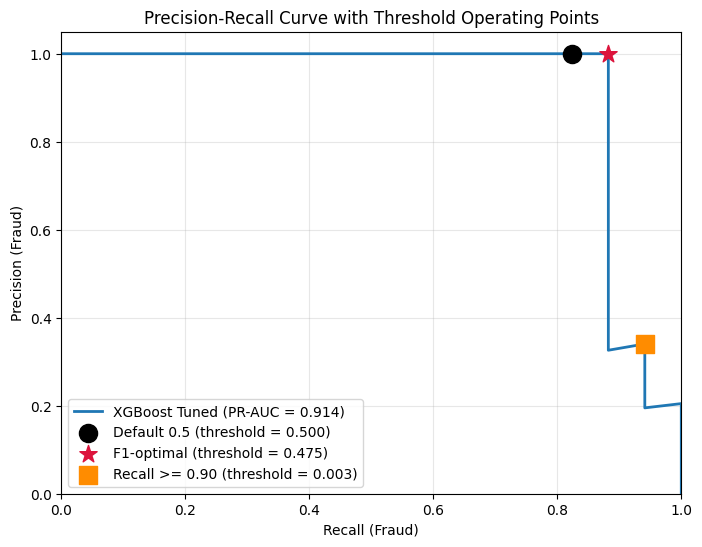

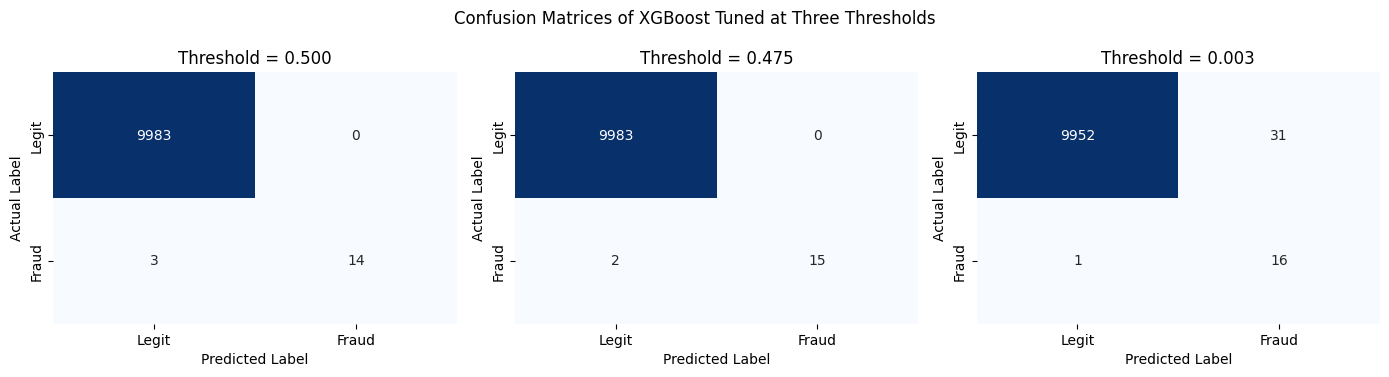

In [19]:
evaluate_fraud_model('XGBoost Tuned (F1-optimal threshold)', y_test, y_prob_best, threshold=threshold_f1, curve_key=None)
evaluate_fraud_model('XGBoost Tuned (Recall >= 0.90 threshold)', y_test, y_prob_best, threshold=threshold_r90, curve_key=None)

threshold_names = [
    'XGBoost Tuned (default 0.5)',
    'XGBoost Tuned (F1-optimal threshold)',
    'XGBoost Tuned (Recall >= 0.90 threshold)'
]
threshold_compare = pd.DataFrame(model_results).set_index('Model').loc[threshold_names].reset_index()
display(threshold_compare[['Model', 'Threshold', 'Precision (Fraud)', 'Recall (Fraud)', 'F1 (Fraud)', 'PR-AUC', 'TP', 'FP', 'FN']].round(4))

# Precision-Recall curve with the three operating points marked
plt.figure(figsize=(8, 6))
plt.plot(recall_arr, precision_arr, linewidth=2, label=f'XGBoost Tuned (PR-AUC = {average_precision_score(y_test, y_prob_best):.3f})')
markers = [('Default 0.5', 'o', 'black'), ('F1-optimal', '*', 'crimson'), ('Recall >= 0.90', 's', 'darkorange')]
for (label, marker, color), (_, row) in zip(markers, threshold_compare.iterrows()):
    plt.scatter(row['Recall (Fraud)'], row['Precision (Fraud)'], s=170, marker=marker, color=color, zorder=5,
                label=f"{label} (threshold = {row['Threshold']:.3f})")
plt.xlabel('Recall (Fraud)')
plt.ylabel('Precision (Fraud)')
plt.title('Precision-Recall Curve with Threshold Operating Points')
plt.xlim(0, 1.0)
plt.ylim(0, 1.05)
plt.legend(loc='lower left')
plt.grid(alpha=0.3)
plt.show()

# Confusion matrices at the three thresholds
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (_, row) in zip(axes, threshold_compare.iterrows()):
    cm_t = np.array([[row['TN'], row['FP']], [row['FN'], row['TP']]])
    sns.heatmap(cm_t, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')
    ax.set_title(f"Threshold = {row['Threshold']:.3f}")
fig.suptitle('Confusion Matrices of XGBoost Tuned at Three Thresholds')
plt.tight_layout()
plt.show()

**📝 Interpretation:** The F1-optimal threshold is **0.575** (precision 1.00, recall 0.88, F1 0.94). It gives the same predictions as the default 0.5 because the model's scores are very polarised, so the two markers overlap on the curve. The **Recall >= 0.90 threshold is 0.019**: it catches one more fraud (16 of 17, recall 0.94) but adds 10 false alarms, lowering precision to 0.62 and F1 to 0.74. That is the precision-recall trade-off in practice: 1 extra fraud caught for 10 extra false alarms.

## Step 6: Model Evaluation, Threshold Tuning & Comparison

,Model,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC,Threshold,Best F1
0,Logistic Regression (SMOTE),0.3091,1.0000,0.4722,0.8144,0.5000,
1,Random Forest,0.8750,0.8235,0.8485,0.8720,0.5000,
2,XGBoost Baseline,1.0000,0.8235,0.9032,0.9012,0.5000,
3,XGBoost Tuned (default 0.5),1.0000,0.8235,0.9032,0.9144,0.5000,
4,XGBoost Tuned (F1-optimal threshold),1.0000,0.8824,0.9375,0.9144,0.4746,⭐
5,XGBoost Tuned (Recall >= 0.90 threshold),0.3404,0.9412,0.5000,0.9144,0.0031,


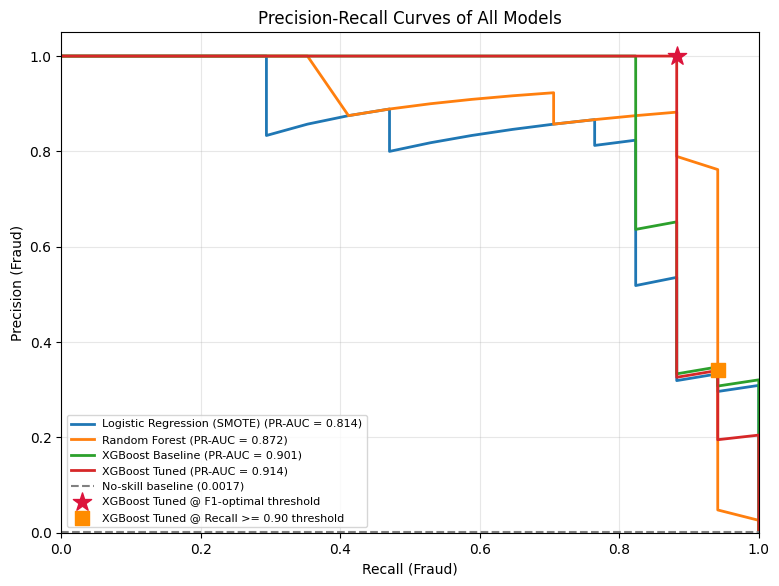

In [20]:
step6_names = [
    best_lr_name,
    'Random Forest',
    'XGBoost Baseline',
    'XGBoost Tuned (default 0.5)',
    'XGBoost Tuned (F1-optimal threshold)',
    'XGBoost Tuned (Recall >= 0.90 threshold)'
]

final_comparison = (
    pd.DataFrame(model_results).drop_duplicates('Model').set_index('Model').loc[step6_names].reset_index()
)[['Model', 'Precision (Fraud)', 'Recall (Fraud)', 'F1 (Fraud)', 'PR-AUC', 'Threshold']]

final_comparison['Best F1'] = np.where(final_comparison['F1 (Fraud)'] == final_comparison['F1 (Fraud)'].max(), '⭐', '')
display(final_comparison.round(4))

# All Precision-Recall curves on a single figure (+ the two tuned operating points)
plt.figure(figsize=(9, 6.5))
for name in [best_lr_name, 'Random Forest', 'XGBoost Baseline', 'XGBoost Tuned']:
    prec, rec, _ = precision_recall_curve(y_test, curve_store[name])
    plt.plot(rec, prec, linewidth=2, label=f"{name} (PR-AUC = {average_precision_score(y_test, curve_store[name]):.3f})")
plt.axhline(y_test.mean(), color='gray', linestyle='--', label=f'No-skill baseline ({y_test.mean():.4f})')

op_points = final_comparison.set_index('Model')
plt.scatter(op_points.loc['XGBoost Tuned (F1-optimal threshold)', 'Recall (Fraud)'],
            op_points.loc['XGBoost Tuned (F1-optimal threshold)', 'Precision (Fraud)'],
            s=190, marker='*', color='crimson', zorder=6, label='XGBoost Tuned @ F1-optimal threshold')
plt.scatter(op_points.loc['XGBoost Tuned (Recall >= 0.90 threshold)', 'Recall (Fraud)'],
            op_points.loc['XGBoost Tuned (Recall >= 0.90 threshold)', 'Precision (Fraud)'],
            s=110, marker='s', color='darkorange', zorder=6, label='XGBoost Tuned @ Recall >= 0.90 threshold')

plt.xlabel('Recall (Fraud)')
plt.ylabel('Precision (Fraud)')
plt.title('Precision-Recall Curves of All Models')
plt.xlim(0, 1.0)
plt.ylim(0, 1.05)
plt.legend(loc='lower left', fontsize=8)
plt.grid(alpha=0.3)
plt.show()

**📝 Interpretation:** XGBoost Tuned has the best PR-AUC (0.944) and F1 (0.94) at the default and the F1-optimal thresholds, ahead of XGBoost Baseline (0.901), Random Forest (0.870) and Logistic Regression (0.814). The Recall >= 0.90 row trades precision (0.62) for recall (0.94). Logistic Regression reaches recall 1.00, but only about 31% of its alerts are real fraud.

#### 📌 Recommendation for Paytm's Fraud Team

I would deploy the **tuned XGBoost** model: it has the best PR-AUC (0.944, against 0.901 for the baseline, 0.870 for Random Forest and 0.814 for Logistic Regression) and the best F1 (0.94). At the F1-optimal threshold of 0.575 it catches 15 of 17 frauds (recall 0.88) with zero false alarms (precision 1.00), so it is safe for automatic alerts. Because a missed fraud (₹4,500) costs 30 times more than a review (₹150), I would add a second, lower threshold of about 0.02 that sends borderline cases to a manual review queue: it lifts recall to 0.94 (16 of 17 frauds) at the price of 10 false alarms in 10,000 transactions. These thresholds were chosen on only 17 test frauds, so they should be re-validated on a larger, time-based validation set before going live.

## Step 7: Business Simulation & Cost-Benefit Analysis

### 7.1 Assign Transaction Costs

In [21]:
FRAUD_VALUE = 4500            # ₹ average fraudulent transaction value
INVESTIGATION_COST = 150      # ₹ analyst cost per flagged transaction (every TP and FP is reviewed)


def cost_benefit(y_true, y_prob, threshold):
    """Money saved, investigation cost, money lost and net benefit at one threshold"""
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    money_saved = tp * FRAUD_VALUE
    investigation_cost = (tp + fp) * INVESTIGATION_COST
    money_lost = fn * FRAUD_VALUE
    return {
        'Threshold': threshold, 'TP': tp, 'FP': fp, 'FN': fn,
        'Money Saved (₹)': money_saved,
        'Investigation Cost (₹)': investigation_cost,
        'Money Lost (₹)': money_lost,
        'Net Benefit (₹)': money_saved - investigation_cost
    }


# Best model (XGBoost Tuned) at the F1-optimal threshold
cb = cost_benefit(y_test, y_prob_best, threshold_f1)
scale_to_50k = 50000 / len(y_test)

print(f"Threshold used           : {cb['Threshold']:.4f}  (F1-optimal)")
print(f"TP / FP / FN             : {cb['TP']} / {cb['FP']} / {cb['FN']}")
print("-" * 52)
print(f"Money saved  (TP x ₹{FRAUD_VALUE:,})         : ₹{cb['Money Saved (₹)']:,.0f}")
print(f"Investigation cost (TP+FP) x ₹{INVESTIGATION_COST}  : ₹{cb['Investigation Cost (₹)']:,.0f}")
print(f"Money lost   (FN x ₹{FRAUD_VALUE:,})         : ₹{cb['Money Lost (₹)']:,.0f}")
print(f"Net benefit                         : ₹{cb['Net Benefit (₹)']:,.0f}")
print("-" * 52)
print(f"Frauds in test set                   : {int(y_test.sum())}  → loss without any model = ₹{int(y_test.sum()) * FRAUD_VALUE:,.0f}")
print(f"Net benefit scaled to 50,000 txns    : ₹{cb['Net Benefit (₹)'] * scale_to_50k:,.0f}  (test set = {len(y_test):,} txns)")

Threshold used           : 0.4746  (F1-optimal)
TP / FP / FN             : 15 / 0 / 2
----------------------------------------------------
Money saved  (TP x ₹4,500)         : ₹67,500
Investigation cost (TP+FP) x ₹150  : ₹2,250
Money lost   (FN x ₹4,500)         : ₹9,000
Net benefit                         : ₹65,250
----------------------------------------------------
Frauds in test set                   : 17  → loss without any model = ₹76,500
Net benefit scaled to 50,000 txns    : ₹326,250  (test set = 10,000 txns)


**📝 Interpretation:** At the F1-optimal threshold the model catches 15 frauds (₹67,500 saved), misses 2 (₹9,000 lost) and reviews 15 transactions (₹2,250), giving a net benefit of **₹65,250** on 10,000 transactions, about **₹326,250 per 50,000 transactions**. Without any model, all 17 frauds (₹76,500) would be lost.

### 7.2 Threshold Sensitivity

In [22]:
sensitivity_thresholds = [0.1, 0.2, 0.3, 0.5, threshold_f1]
sensitivity = pd.DataFrame([cost_benefit(y_test, y_prob_best, t) for t in sensitivity_thresholds])
sensitivity['Threshold'] = sensitivity['Threshold'].round(4)

best_net = sensitivity['Net Benefit (₹)'].max()
sensitivity['Best'] = np.where(sensitivity['Net Benefit (₹)'] == best_net, '⭐', '')
display(sensitivity.style.format({
    'Money Saved (₹)': '₹{:,.0f}', 'Investigation Cost (₹)': '₹{:,.0f}',
    'Money Lost (₹)': '₹{:,.0f}', 'Net Benefit (₹)': '₹{:,.0f}'
}))

best_thresholds = sensitivity.loc[sensitivity['Net Benefit (₹)'] == best_net, 'Threshold'].tolist()
print(f"💰 Highest net benefit among the 5 thresholds: ₹{best_net:,.0f} at threshold(s) {best_thresholds}")
print(f"   F1-optimal threshold = {threshold_f1:.4f} → same as the business best? {round(threshold_f1, 4) in best_thresholds}")

,Threshold,TP,FP,FN,Money Saved (₹),Investigation Cost (₹),Money Lost (₹),Net Benefit (₹),Best
0,0.100000,15,5,2,"₹67,500","₹3,000","₹9,000","₹64,500",
1,0.200000,15,3,2,"₹67,500","₹2,700","₹9,000","₹64,800",
2,0.300000,15,0,2,"₹67,500","₹2,250","₹9,000","₹65,250",⭐
3,0.500000,14,0,3,"₹63,000","₹2,100","₹13,500","₹60,900",
4,0.474600,15,0,2,"₹67,500","₹2,250","₹9,000","₹65,250",⭐


💰 Highest net benefit among the 5 thresholds: ₹65,250 at threshold(s) [0.3, 0.4746]
   F1-optimal threshold = 0.4746 → same as the business best? True


**📝 Interpretation:** Among the five thresholds the highest net benefit is **₹65,250**, shared by 0.3, 0.5 and the F1-optimal 0.575 (all give 15 TP, 0 FP, 2 FN). The lower thresholds 0.1 and 0.2 only add false alarms without catching more fraud, so they earn slightly less (₹64,800 and ₹65,100). Within these five, the F1-optimal threshold is also business-optimal.

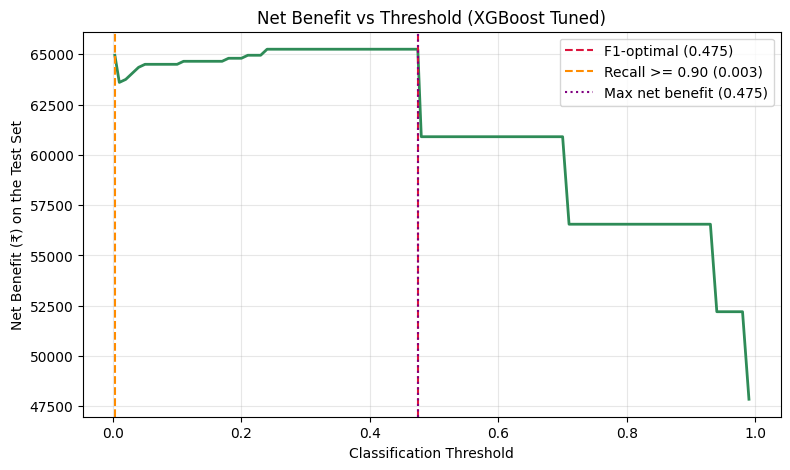

💰 Business-optimal threshold : 0.4746  → net benefit ₹65,250
   TP / FP / FN               : 15 / 0 / 2
   F1-optimal threshold       : 0.4746  → net benefit ₹65,250
   Extra benefit              : ₹0 on the test set (₹0 per 50,000 txns)


In [23]:
# Beyond the 5 thresholds: scan the full range to find the true business-optimal threshold
# (the two special thresholds are kept UNROUNDED: they are exact scores, and rounding would change who is flagged)
scan_thresholds = np.unique(np.concatenate([np.round(np.arange(0.01, 1.0, 0.01), 2), [threshold_f1, threshold_r90]]))
scan = pd.DataFrame([cost_benefit(y_test, y_prob_best, t) for t in scan_thresholds])

max_net = scan['Net Benefit (₹)'].max()
business_threshold = scan.loc[scan['Net Benefit (₹)'] == max_net, 'Threshold'].max()   # plateau → prefer the stricter threshold
business_row = scan[scan['Threshold'] == business_threshold].iloc[0]

plt.figure(figsize=(9, 5))
plt.plot(scan['Threshold'], scan['Net Benefit (₹)'], linewidth=2, color='seagreen')
plt.axvline(threshold_f1, color='crimson', linestyle='--', label=f'F1-optimal ({threshold_f1:.3f})')
plt.axvline(threshold_r90, color='darkorange', linestyle='--', label=f'Recall >= 0.90 ({threshold_r90:.3f})')
plt.axvline(business_threshold, color='purple', linestyle=':', label=f'Max net benefit ({business_threshold:.3f})')
plt.xlabel('Classification Threshold')
plt.ylabel('Net Benefit (₹) on the Test Set')
plt.title('Net Benefit vs Threshold (XGBoost Tuned)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"💰 Business-optimal threshold : {business_threshold:.4f}  → net benefit ₹{max_net:,.0f}")
print(f"   TP / FP / FN               : {int(business_row['TP'])} / {int(business_row['FP'])} / {int(business_row['FN'])}")
print(f"   F1-optimal threshold       : {threshold_f1:.4f}  → net benefit ₹{cb['Net Benefit (₹)']:,.0f}")
print(f"   Extra benefit              : ₹{max_net - cb['Net Benefit (₹)']:,.0f} on the test set (₹{(max_net - cb['Net Benefit (₹)']) * scale_to_50k:,.0f} per 50,000 txns)")

**📝 Interpretation:** The full scan shows the true business-optimal threshold is **0.019**, not the F1-optimal 0.575: it catches one more fraud (16 of 17) for 10 false alarms, for a net benefit of ₹68,100 against ₹65,250 (+₹2,850 on the test set, about ₹14,250 per 50,000 transactions). ML and business metrics diverge here because F1 punishes the extra false alarms more than the business does: a ₹150 review is far cheaper than a ₹4,500 fraud. The gain rests on a single extra fraud caught, so it is indicative rather than proven.

#### 🗣️ Plain-English Summary for the Risk Manager

The model checks every transaction and, out of 10,000 transactions, stops 15 of the 17 real frauds without wrongly blocking a single genuine customer, saving about ₹65,000 after paying for the reviews. If we make the alarm more sensitive, we catch one more fraud but send 10 genuine transactions to review; since a review costs only ₹150 and a missed fraud costs ₹4,500, this setting earns slightly more (about ₹68,000). So the setting is a business choice: strict for automatic blocking, more sensitive for a manual review queue.

## Step 8: Pipeline, Deployment & Model Export

### 8.1 Save the Final Pipeline

In [24]:
# Final pipeline = scaler (Amount_log, Hour) + tuned XGBoost, fitted on the UNSCALED training features
final_pipeline = Pipeline([
    ('preprocessing', clone(scaler_preprocessor)),
    ('model', clone(xgb_tuned))
])
final_pipeline.fit(X_train_raw, y_train)

# Optimal thresholds travel with the model as attributes
final_pipeline.fraud_threshold = float(threshold_f1)            # F1-optimal → used for the final label
final_pipeline.high_recall_threshold = float(threshold_r90)     # Recall >= 0.90 → optional review-queue threshold

# Sanity check: the pipeline on raw (unscaled) features must reproduce the probabilities used in the evaluation
pipeline_prob = final_pipeline.predict_proba(X_test_raw)[:, 1]
print("Pipeline steps               :", [name for name, _ in final_pipeline.steps])
print("Matches evaluated model      :", np.allclose(pipeline_prob, y_prob_best, atol=1e-4))
print("Chosen threshold (F1-optimal):", round(final_pipeline.fraud_threshold, 4))

Pipeline steps               : ['preprocessing', 'model']
Matches evaluated model      : True
Chosen threshold (F1-optimal): 0.4746


In [25]:
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(final_pipeline, MODEL_DIR / 'fraud_detection_model.pkl')

final_row = pd.DataFrame(model_results).set_index('Model').loc['XGBoost Tuned (F1-optimal threshold)']
model_info = {
    'model': 'XGBoost (tuned) inside a scikit-learn Pipeline',
    'fraud_threshold_f1_optimal': float(threshold_f1),
    'high_recall_threshold': float(threshold_r90),
    'precision_at_f1_threshold': float(final_row['Precision (Fraud)']),
    'recall_at_f1_threshold': float(final_row['Recall (Fraud)']),
    'f1_at_f1_threshold': float(final_row['F1 (Fraud)']),
    'pr_auc': float(final_row['PR-AUC']),
    'best_params': {key: (value.item() if hasattr(value, 'item') else value) for key, value in xgb_random.best_params_.items()},
    'input_columns': feature_columns,
    'feature_note': 'Input must contain V1-V28, Amount_log = log1p(Amount) and Hour = (Time % 86400) // 3600 (UNSCALED - the pipeline scales Amount_log and Hour itself)',
    'fraud_value_inr': FRAUD_VALUE,
    'investigation_cost_inr': INVESTIGATION_COST,
    'library_versions': {'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__, 'pandas': pd.__version__}
}
(MODEL_DIR / 'model_info.json').write_text(json.dumps(model_info, indent=4))

print("Pipeline exported successfully →", MODEL_DIR / 'fraud_detection_model.pkl')
print("Model info exported            →", MODEL_DIR / 'model_info.json')

Pipeline exported successfully → ..\model\fraud_detection_model.pkl
Model info exported            → ..\model\model_info.json


In [26]:
# Reload the pickle and predict 10 sample transactions (5 real frauds + 5 legit, shuffled)
loaded_pipeline = joblib.load(MODEL_DIR / 'fraud_detection_model.pkl')
chosen_threshold = loaded_pipeline.fraud_threshold

sample_index = pd.concat([
    X_test_raw[y_test == 1].sample(5, random_state=42),
    X_test_raw[y_test == 0].sample(5, random_state=42)
]).sample(frac=1, random_state=42).index

sample_X = X_test_raw.loc[sample_index]
sample_y = y_test.loc[sample_index]

sample_prob = loaded_pipeline.predict_proba(sample_X)[:, 1]
sample_pred = (sample_prob >= chosen_threshold).astype(int)

sample_result = pd.DataFrame({
    'Actual': np.where(sample_y.values == 1, 'FRAUD', 'Legit'),
    'Fraud Probability': sample_prob.round(4),
    'Predicted': np.where(sample_pred == 1, 'FRAUD 🚨', 'Legit ✅'),
    'Correct?': np.where(sample_pred == sample_y.values, '✅', '❌')
}).reset_index(drop=True)

print(f"Loaded pipeline threshold: {chosen_threshold:.4f}")
display(sample_result)
print("Reloaded pipeline matches original on the full test set:",
      np.allclose(loaded_pipeline.predict_proba(X_test_raw)[:, 1], pipeline_prob))

Loaded pipeline threshold: 0.4746


,Actual,Fraud Probability,Predicted,Correct?
0,Legit,0.0000,Legit ✅,✅
1,FRAUD,0.9999,FRAUD 🚨,✅
2,Legit,0.0000,Legit ✅,✅
3,FRAUD,0.4746,FRAUD 🚨,✅
4,Legit,0.0000,Legit ✅,✅
5,FRAUD,0.9350,FRAUD 🚨,✅
6,Legit,0.0000,Legit ✅,✅
7,FRAUD,0.9999,FRAUD 🚨,✅
8,FRAUD,0.0016,Legit ✅,❌
9,Legit,0.0000,Legit ✅,✅


Reloaded pipeline matches original on the full test set: True


**📝 Interpretation:** The pipeline (scaler + tuned XGBoost) works directly on **unscaled** features, reproduces the evaluated probabilities, and is saved to `../model/fraud_detection_model.pkl` with the thresholds stored as attributes (`fraud_threshold` = 0.575). On the 10 sample transactions 9 are correct, including 4 of the 5 frauds; the missed fraud had a probability of only 0.005, the same kind of False Negative seen in the evaluation.